# Données réelles : options sur le S&P 500

On applique les outils du projet à des options réelles sur le S&P 500 (SPX) :
1. téléchargement des calls avec `yfinance`, enregistrés une fois pour toutes dans `data/spx_options.csv` ;
2. volatilité implicite et smile de marché ;
3. lissage du smile et volatilité locale par la formule de Dupire ;
4. règle du double de la pente à la monnaie ;
5. prix d'un call vanille et d'un call barrière up-and-out, sous Black-Scholes et sous Dupire.

In [1]:
import os
import sys
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

sys.path.append("../src")
from dupire.black_scholes import bs_implied_vol, bs_call_price
from dupire.local_vol import local_vol_from_prices, fill_local_vol_surface, interpolate_local_vol
from dupire.monte_carlo import simulate_paths, mc_price, european_call_payoff, barrier_up_and_out_call_payoff

## Paramètres

In [2]:
# Paramètres financiers
r = 0.045                        # taux sans risque américain
q = 0.015                        # rendement du dividende du S&P 500

# Données de marché
FICHIER = "../data/spx_options.csv"
CIBLES_JOURS = [30, 60, 150, 240]   # maturités visées, en jours
K_MIN = 0.85                     # strikes gardés entre 85 % et 115 % du spot
K_MAX = 1.15
VOL_MIN = 0.05                   # volatilités implicites aberrantes retirées
VOL_MAX = 0.60

# Lissage et formule de Dupire
N_K = 51                         # nombre de strikes de la grille
DEGRE = 2                        # degré du polynôme de lissage
I_PENTE = 1                      # maturité utilisée pour la règle du double de la pente

# Monte Carlo
I_BARRIERE = 2                   # maturité des deux calls
K_BAR = 7700.0                   # strike
B_BAR = 8200.0                   # barrière
N_PAS = 100
N_TRAJ = 30000
GRAINE = 2026

## 1. Données de marché

Les cotations changent en continu. On les télécharge une seule fois et on les enregistre dans un CSV : les exécutions suivantes relisent ce fichier, ce qui rend les résultats reproductibles. Pour mettre à jour les données, il suffit de supprimer le fichier.

In [3]:
if not os.path.exists(FICHIER):
    spx = yf.Ticker("^SPX")
    spot = float(spx.history(period="1d")["Close"].iloc[-1])
    today = datetime.now()

    # Nombre de jours avant chaque maturité cotée
    jours = np.zeros(len(spx.options))
    for n in range(len(spx.options)):
        jours[n] = (datetime.strptime(spx.options[n], "%Y-%m-%d") - today).days

    # Pour chaque cible, la maturité cotée la plus proche
    maturites = []
    for c in CIBLES_JOURS:
        m = spx.options[np.argmin(np.abs(jours - c))]
        if m not in maturites:
            maturites.append(m)

    # Calls cotés (bid et ask valides) dans la zone de strikes retenue
    liste = []
    for m in maturites:
        calls = spx.option_chain(m).calls
        ok = (calls["bid"] > 0) & (calls["ask"] > calls["bid"])
        ok = ok & (calls["strike"] >= K_MIN * spot) & (calls["strike"] <= K_MAX * spot)
        df = calls[ok][["strike", "bid", "ask"]].copy()
        df["mid"] = (df["bid"] + df["ask"]) / 2
        df["T"] = (datetime.strptime(m, "%Y-%m-%d") - today).days / 365.25
        df["maturite"] = m
        df["S0"] = spot
        df["date"] = today.strftime("%Y-%m-%d")
        liste.append(df)
    pd.concat(liste).to_csv(FICHIER, index=False)

donnees = pd.read_csv(FICHIER)
S0 = donnees["S0"][0]
maturites = list(donnees["maturite"].unique())
print("Données du", donnees["date"][0], ": S0 =", round(S0, 2))
print("Maturités :", maturites)
print("Nombre de calls :", len(donnees))

Données du 2026-10-29 : S0 = 7720.39
Maturités : ['2026-11-30', '2026-12-31', '2027-03-31', '2027-06-30']
Nombre de calls : 1127


## 2. Volatilité implicite

Pour chaque call, on cherche la volatilité qui redonne le prix milieu (mid) avec la formule de Black-Scholes. `bs_implied_vol` renvoie NaN pour un prix hors des bornes d'arbitrage. Ces options sont retirées, comme les volatilités aberrantes.

Volatilités implicites retenues : 1063


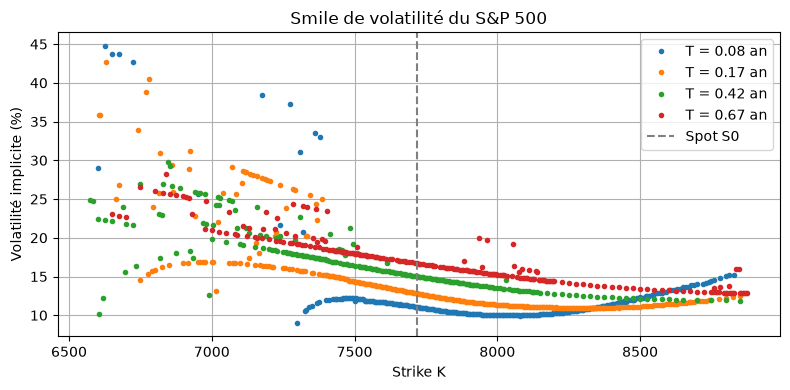

In [4]:
mid = donnees["mid"].values
strike = donnees["strike"].values
T = donnees["T"].values

iv = np.zeros(len(donnees))
for n in range(len(donnees)):
    iv[n] = bs_implied_vol(mid[n], S0, strike[n], T[n], r, q)
donnees["iv"] = iv

# Une comparaison avec NaN est fausse : les NaN partent avec les valeurs aberrantes
donnees = donnees[(donnees["iv"] > VOL_MIN) & (donnees["iv"] < VOL_MAX)]
print("Volatilités implicites retenues :", len(donnees))

fig, ax = plt.subplots(figsize=(8, 4))
for i in range(len(maturites)):
    sub = donnees[donnees["maturite"] == maturites[i]]
    ax.plot(sub["strike"], sub["iv"] * 100, "o", markersize=3, label=f"T = {sub['T'].iloc[0]:.2f} an")
ax.axvline(S0, color="gray", linestyle="--", label="Spot S0")
ax.set_xlabel("Strike K")
ax.set_ylabel("Volatilité implicite (%)")
ax.set_title("Smile de volatilité du S&P 500")
ax.legend()
ax.grid(True)
plt.tight_layout()
fig.savefig("../report/figures/fig_smile_spx_marche.png", dpi=150)
plt.show()

## 3. Lissage et volatilité locale

La formule de Dupire dérive deux fois les prix en $K$. Sur des cotations bruitées, ces dérivées oscillent et donnent des variances négatives. On ajuste donc une parabole sur chaque smile, puis on recalcule des prix lisses avec Black-Scholes avant d'appliquer la formule.

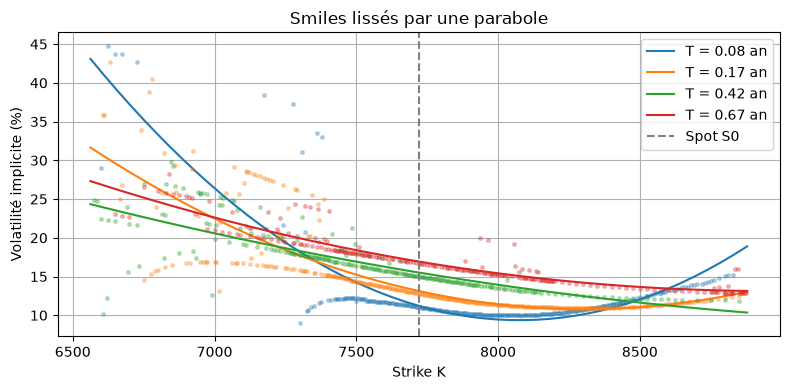

In [5]:
K_grille = np.linspace(K_MIN * S0, K_MAX * S0, N_K)
T_grille = np.zeros(len(maturites))
iv_lisse = np.zeros((len(maturites), N_K))
C_grille = np.zeros((len(maturites), N_K))

fig, ax = plt.subplots(figsize=(8, 4))
for i in range(len(maturites)):
    sub = donnees[donnees["maturite"] == maturites[i]]
    T_grille[i] = sub["T"].iloc[0]
    # Parabole ajustée sur le smile, puis prix lisses
    coef = np.polyfit(sub["strike"], sub["iv"], DEGRE)
    iv_lisse[i] = np.polyval(coef, K_grille)
    C_grille[i] = bs_call_price(S0, K_grille, T_grille[i], r, q, iv_lisse[i])
    ax.plot(sub["strike"], sub["iv"] * 100, "o", color=f"C{i}", markersize=2.5, alpha=0.3)
    ax.plot(K_grille, iv_lisse[i] * 100, color=f"C{i}", label=f"T = {T_grille[i]:.2f} an")
ax.axvline(S0, color="gray", linestyle="--", label="Spot S0")
ax.set_xlabel("Strike K")
ax.set_ylabel("Volatilité implicite (%)")
ax.set_title("Smiles lissés par une parabole")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

In [6]:
# Formule de Dupire. La première maturité n'a pas de dérivée centrée en T : elle reste NaN
sigma_loc = local_vol_from_prices(K_grille, T_grille, C_grille, r, q=q)

# Points où la formule s'applique : maturités 2 à 4, strikes intérieurs
calculables = sigma_loc[1:, 1:-1]
print("Points rejetés (variance négative ou densité nulle) :", np.sum(np.isnan(calculables)), "sur", calculables.size)

# NaN remplacés par interpolation : la première maturité recopie la deuxième
sigma_loc = fill_local_vol_surface(K_grille, T_grille, sigma_loc)

Points rejetés (variance négative ou densité nulle) : 0 sur 147


## 4. Règle du double de la pente

Pour les maturités courtes, à la monnaie, la pente de la volatilité locale en $K$ est environ le double de celle de la volatilité implicite.

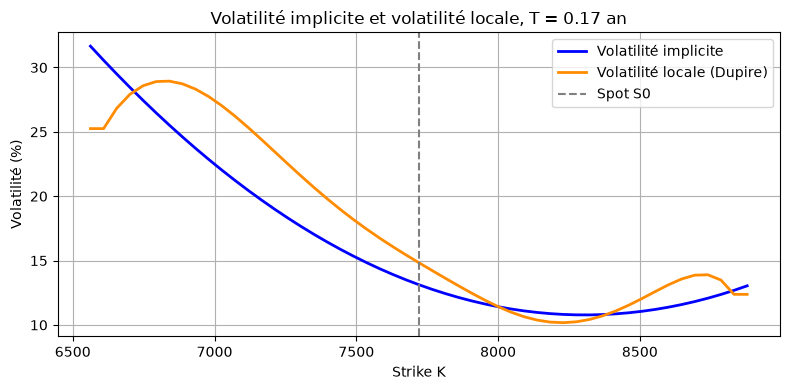

Pente de la volatilité implicite : -8.04e-05
Pente de la volatilité locale    : -1.32e-04
Rapport                          : 1.64  (environ 2 attendu)


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(K_grille, iv_lisse[I_PENTE] * 100, color="blue", lw=2, label="Volatilité implicite")
ax.plot(K_grille, sigma_loc[I_PENTE] * 100, color="darkorange", lw=2, label="Volatilité locale (Dupire)")
ax.axvline(S0, color="gray", linestyle="--", label="Spot S0")
ax.set_xlabel("Strike K")
ax.set_ylabel("Volatilité (%)")
ax.set_title(f"Volatilité implicite et volatilité locale, T = {T_grille[I_PENTE]:.2f} an")
ax.legend()
ax.grid(True)
plt.tight_layout()
fig.savefig("../report/figures/fig_comparaison_vol_spx.png", dpi=150)
plt.show()

# Pentes à la monnaie par différences centrées
j = np.argmin(np.abs(K_grille - S0))
h = K_grille[j + 1] - K_grille[j - 1]
pente_imp = (iv_lisse[I_PENTE, j + 1] - iv_lisse[I_PENTE, j - 1]) / h
pente_loc = (sigma_loc[I_PENTE, j + 1] - sigma_loc[I_PENTE, j - 1]) / h
print(f"Pente de la volatilité implicite : {pente_imp:.2e}")
print(f"Pente de la volatilité locale    : {pente_loc:.2e}")
print(f"Rapport                          : {pente_loc / pente_imp:.2f}  (environ 2 attendu)")

## 5. Call vanille et call barrière

On simule le S&P 500 par Monte Carlo sous deux modèles : Black-Scholes avec la volatilité implicite à la monnaie, et Dupire avec la volatilité locale calculée plus haut.
- Le call vanille est coté : il sert de contrôle, car sous Dupire son prix doit retrouver le prix de marché.
- Le call barrière up-and-out est désactivé si l'indice touche la barrière $B$. Il n'est pas coté : seul un modèle peut en donner le prix.

In [8]:
T_bar = T_grille[I_BARRIERE]
sub = donnees[donnees["maturite"] == maturites[I_BARRIERE]]

# Prix de marché du call vanille (interpolé si le strike n'est pas coté)
prix_marche = np.interp(K_BAR, sub["strike"], sub["mid"])
bid = np.interp(K_BAR, sub["strike"], sub["bid"])
ask = np.interp(K_BAR, sub["strike"], sub["ask"])

# Volatilité de marché et volatilité de la parabole en K_BAR, et prix lissé correspondant
iv_marche = np.interp(K_BAR, sub["strike"], sub["iv"])
iv_parabole = np.interp(K_BAR, K_grille, iv_lisse[I_BARRIERE])
prix_lisse = bs_call_price(S0, K_BAR, T_bar, r, q, iv_parabole)

# Black-Scholes : volatilité implicite lissée à la monnaie
vol_atm = np.interp(S0, K_grille, iv_lisse[I_BARRIERE])

print("Volatilité locale (%) en S0, K et B :")
for i in range(len(maturites)):
    v0 = 100 * np.interp(S0, K_grille, sigma_loc[i])
    vk = 100 * np.interp(K_BAR, K_grille, sigma_loc[i])
    vb = 100 * np.interp(B_BAR, K_grille, sigma_loc[i])
    print(f"  T = {T_grille[i]:.2f} an : {v0:.1f}   {vk:.1f}   {vb:.1f}")
print()


def vol_bs(S, t):
    return vol_atm


def vol_dupire(S, t):
    return interpolate_local_vol(S, t, K_grille, T_grille, sigma_loc)


# Mêmes nombres aléatoires pour les deux modèles
np.random.seed(GRAINE)
paths_bs = simulate_paths(S0, r, vol_bs, T_bar, N_PAS, N_TRAJ, q)
np.random.seed(GRAINE)
paths_dup = simulate_paths(S0, r, vol_dupire, T_bar, N_PAS, N_TRAJ, q)

# mc_price renvoie (prix, borne basse, borne haute) de l'intervalle de confiance à 95 %
vanille_bs = mc_price(european_call_payoff(paths_bs, K_BAR), r, T_bar)
vanille_dup = mc_price(european_call_payoff(paths_dup, K_BAR), r, T_bar)
barriere_bs = mc_price(barrier_up_and_out_call_payoff(paths_bs, K_BAR, B_BAR), r, T_bar)
barriere_dup = mc_price(barrier_up_and_out_call_payoff(paths_dup, K_BAR, B_BAR), r, T_bar)

# Proportion de trajectoires qui touchent la barrière, et qui finissent entre K et B sans la toucher
ko_bs = np.mean(np.max(paths_bs, axis=1) >= B_BAR)
ko_dup = np.mean(np.max(paths_dup, axis=1) >= B_BAR)
entre_bs = np.mean((np.max(paths_bs, axis=1) < B_BAR) & (paths_bs[:, -1] > K_BAR))
entre_dup = np.mean((np.max(paths_dup, axis=1) < B_BAR) & (paths_dup[:, -1] > K_BAR))

print(f"Volatilité à la monnaie utilisée par Black-Scholes : {100 * vol_atm:.2f} %")
print()
print(f"Call vanille, K = {K_BAR:.0f}, T = {T_bar:.2f} an")
print(f"  Marché        : {prix_marche:.2f}   (bid {bid:.2f}, ask {ask:.2f})   volatilité implicite {100 * iv_marche:.2f} %")
print(f"  Prix lissé    : {prix_lisse:.2f}   volatilité de la parabole {100 * iv_parabole:.2f} %")
print(f"  Black-Scholes : {vanille_bs[0]:.2f}   IC [{vanille_bs[1]:.2f}, {vanille_bs[2]:.2f}]")
print(f"  Dupire        : {vanille_dup[0]:.2f}   IC [{vanille_dup[1]:.2f}, {vanille_dup[2]:.2f}]")
print()
print(f"Call barrière up-and-out, K = {K_BAR:.0f}, B = {B_BAR:.0f}")
print(f"  Black-Scholes : {barriere_bs[0]:.2f}   IC [{barriere_bs[1]:.2f}, {barriere_bs[2]:.2f}]")
print(f"  Dupire        : {barriere_dup[0]:.2f}   IC [{barriere_dup[1]:.2f}, {barriere_dup[2]:.2f}]")
print()
print("Trajectoires désactivées            :", f"BS {100 * ko_bs:.1f} %,  Dupire {100 * ko_dup:.1f} %")
print("Trajectoires finies entre K et B    :", f"BS {100 * entre_bs:.1f} %,  Dupire {100 * entre_dup:.1f} %")

Volatilité locale (%) en S0, K et B :
  T = 0.08 an : 14.8   15.1   10.2
  T = 0.17 an : 14.8   15.1   10.2
  T = 0.42 an : 17.9   18.2   12.6
  T = 0.67 an : 17.1   17.4   15.1



Volatilité à la monnaie utilisée par Black-Scholes : 15.51 %

Call vanille, K = 7700, T = 0.42 an
  Marché        : 357.55   (bid 356.40, ask 358.70)   volatilité implicite 15.13 %
  Prix lissé    : 367.38   volatilité de la parabole 15.64 %
  Black-Scholes : 366.16   IC [360.29, 372.03]
  Dupire        : 374.49   IC [369.80, 379.19]

Call barrière up-and-out, K = 7700, B = 8200
  Black-Scholes : 16.33   IC [15.61, 17.06]
  Dupire        : 26.67   IC [25.73, 27.62]

Trajectoires désactivées            : BS 53.2 %,  Dupire 56.7 %
Trajectoires finies entre K et B    : BS 8.9 %,  Dupire 12.7 %


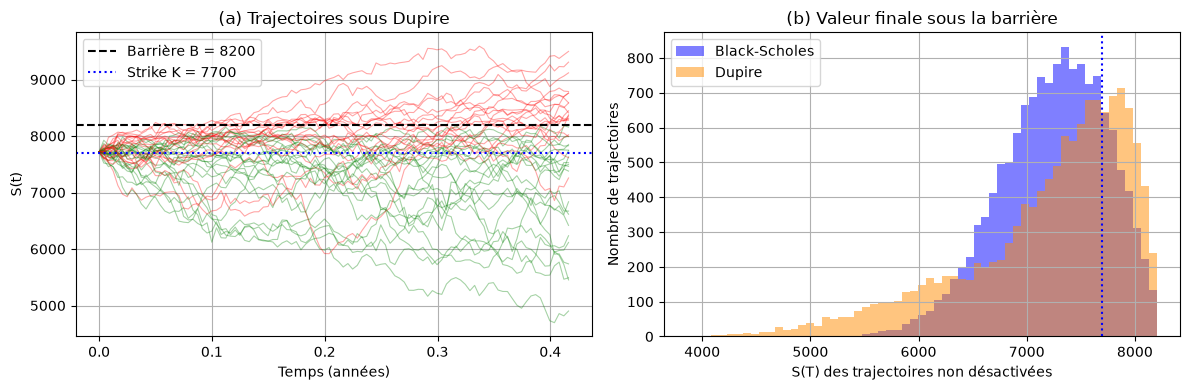

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# (a) 40 trajectoires sous Dupire : vertes si elles restent sous la barrière, rouges sinon
temps = np.linspace(0, T_bar, N_PAS + 1)
for n in range(40):
    if np.max(paths_dup[n]) < B_BAR:
        couleur = "green"
    else:
        couleur = "red"
    ax1.plot(temps, paths_dup[n], color=couleur, alpha=0.35, lw=0.8)
ax1.axhline(B_BAR, color="black", linestyle="--", label=f"Barrière B = {B_BAR:.0f}")
ax1.axhline(K_BAR, color="blue", linestyle=":", label=f"Strike K = {K_BAR:.0f}")
ax1.set_xlabel("Temps (années)")
ax1.set_ylabel("S(t)")
ax1.set_title("(a) Trajectoires sous Dupire")
ax1.legend(loc="upper left")
ax1.grid(True)

# (b) Valeur finale des trajectoires restées sous la barrière
reste_bs = np.max(paths_bs, axis=1) < B_BAR
reste_dup = np.max(paths_dup, axis=1) < B_BAR
classes = np.linspace(0.5 * S0, B_BAR, 60)
ax2.hist(paths_bs[reste_bs, -1], bins=classes, alpha=0.5, color="blue", label="Black-Scholes")
ax2.hist(paths_dup[reste_dup, -1], bins=classes, alpha=0.5, color="darkorange", label="Dupire")
ax2.axvline(K_BAR, color="blue", linestyle=":")
ax2.set_xlabel("S(T) des trajectoires non désactivées")
ax2.set_ylabel("Nombre de trajectoires")
ax2.set_title("(b) Valeur finale sous la barrière")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
fig.savefig("../report/figures/fig_barriere_spx.png", dpi=150)
plt.show()

## Conclusion

**Smile et volatilité locale.** Le S&P 500 a un skew marqué : la volatilité implicite baisse quand le strike monte. Après lissage, la formule de Dupire ne rejette aucun point (0 sur 147). À $T = 0{,}17$ an, la pente de la volatilité locale à la monnaie vaut 1,64 fois celle de la volatilité implicite, proche du facteur 2 attendu pour les maturités courtes.

**Call vanille (contrôle).** Le marché cote 357,55, soit une volatilité implicite de 15,13 %. La parabole donne 15,64 % en $K = 7700$, donc un prix lissé de 367,38 : le lissage, tiré par les calls dans la monnaie très bruités, surestime le prix de 2,7 %. Dupire donne 374,49, encore 2 % au-dessus du prix lissé et hors de son intervalle de confiance : la surface de volatilité locale ne repose que sur 4 maturités, et la première recopie la deuxième. La calibration n'est donc qu'approchée.

**Call barrière.** Dupire donne 26,67 contre 16,33 pour Black-Scholes, soit 63 % de plus, avec des intervalles de confiance disjoints. L'écart vient du skew : sous Dupire, la volatilité baisse quand l'indice monte. Près de la barrière, elle n'est que de 10 à 13 %, contre 15,5 % partout sous Black-Scholes. Les trajectoires qui montent au-dessus de $K$ restent donc plus souvent sous la barrière : 12,7 % finissent entre $K$ et $B$ sous Dupire, contre 8,9 % sous Black-Scholes. La part de trajectoires désactivées est pourtant un peu plus forte sous Dupire (56,7 % contre 53,2 %), car près du spot la volatilité locale atteint 18 % à $T = 0{,}42$ an.

**Limites.** Un seul jour de données (29/10/2026), $r$ et $q$ fixés à la main, seulement des calls (sous le spot, les puts hors de la monnaie seraient plus fiables que les calls dans la monnaie) et 4 maturités.